In [1]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis

Foram criadas 3 pastas a partir das imagens originais. Uma das pastas recebeu as imagens sem marcador, outra pasta recebeu as imagens marcadas sem rótulo e a terceira pasta recebeu as imagens marcadas com os rótulos. Nesse notebook, estamos trabalhando com 40 (iniciais) imagens marcadas com os rótulos.

In [2]:
novas_imagens = "./data/realcadas_verde_HUVEC/"
img_key = 0 #Chave da primeira imagem

lista_novas_img = os.listdir(novas_imagens) #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens
#lista_novas_img

38

Visualização das imagens (x): Melhor resolução 300x300

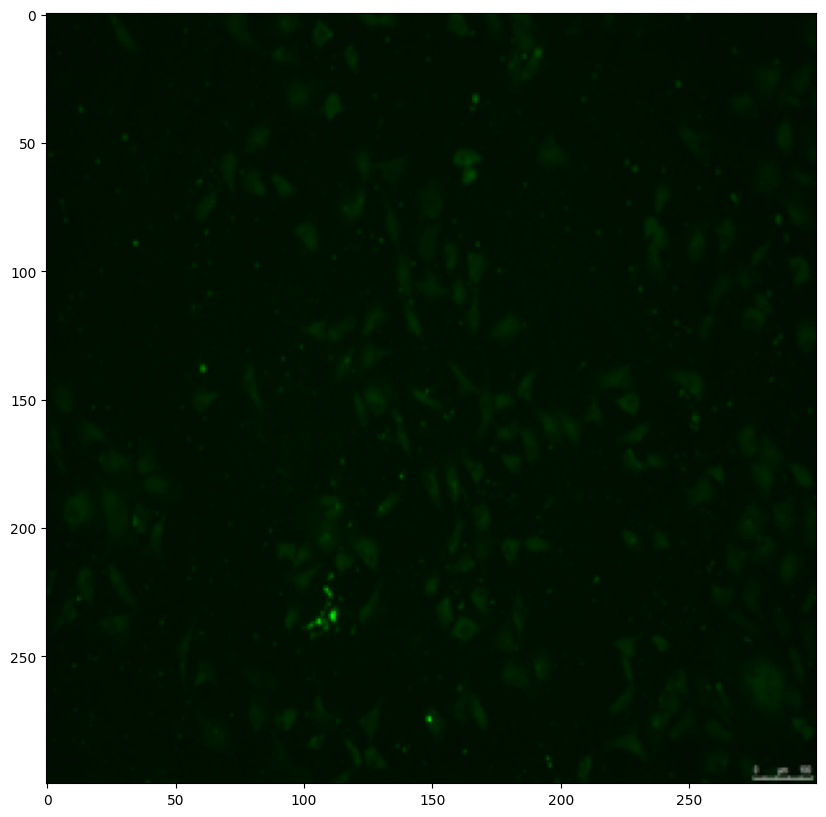

In [3]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

#1. Original orientation of the image.

In [4]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img] #cortando informações da imagem
y_rotulo_imagem = [(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = y_rotulo_imagem
print(len(y_rotulo_imagem)) #verificando o numero de rótulos corresponde o numero de imagens
print(y_rotulo_imagem)

38
['0.070038', '0.068888', '0.070178', '0.067018', '0.065635', '0.067453', '0.069308', '0.068375', '0.068257', '0.071546', '0.068760', '0.071201', '0.072419', '0.070659', '0.070864', '0.063423', '0.117536', '0.103083', '0.078077', '0.101537', '0.159318', '0.119242', '0.109643', '0.095412', '0.091715', '0.109804', '0.113195', '0.144051', '0.338015', '0.067398', '0.067406', '0.067253', '0.0689', '0.068904', '0.071255', '0.070044', '0.071514', '0.071977']


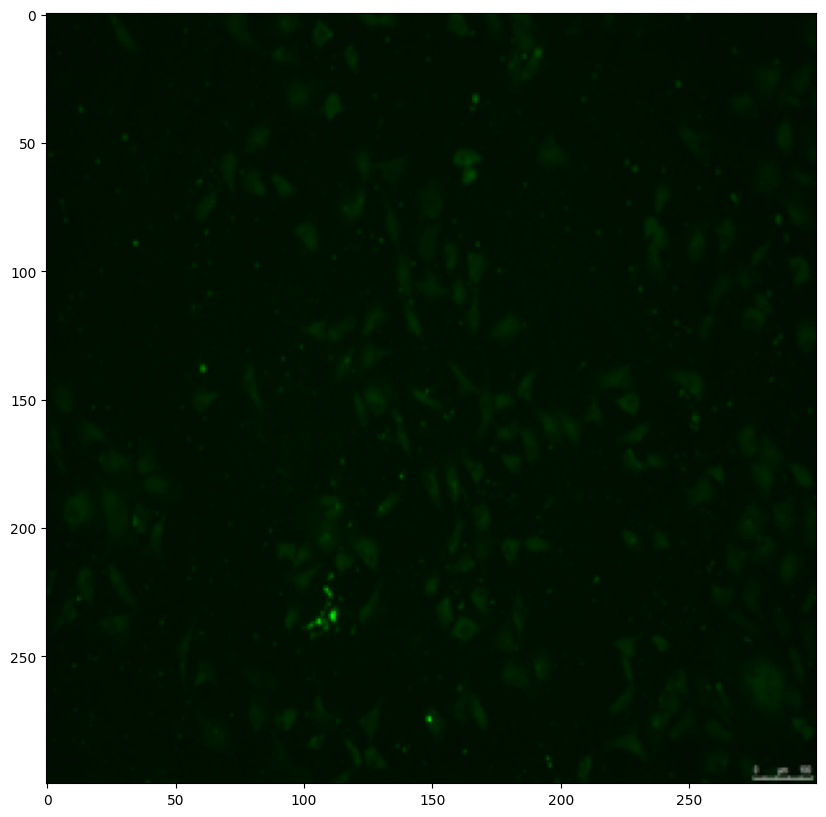

In [5]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

Formatting all images that are saved in the directory into an array

In [6]:
lista_imagens_camp_claro = [] #lista vazia onde vai ser armazenado os dados
for file in lista_novas_img[:]:  #laço pra salvar todas as imagens
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test) #abrir a imagem
    img = img.resize(resize_img) #formatando em 300x300
    img = np.asarray(img)[:,:,:3] #formatando em array
    lista_imagens_camp_claro.append(img)  #adicionando cada imagem
np.asarray(lista_imagens_camp_claro).shape #verificando quantas imagens foram salvas em qual tamnho e camadas

(38, 300, 300, 3)

In [7]:
data = timeProcess()[1]
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_img_100_resized_regre_campo_claro_'+data+'.gz')

['./data/realcadas_verde_HUVEC/lista_img_100_resized_regre_campo_claro_2026-10-17.gz']

#2. Saving inverted images from left to right

label (80 - doubled) - dobrando o numero de rótulos

In [8]:
#dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

76

In [9]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(76, 300, 300, 3)

#3. Saving inverted images from bottom to top

y = label (120 - doubled)

In [10]:
#dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

114

In [11]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(114, 300, 300, 3)

# 4. Saving the images flipped upside down.

label (160 - doubled) - dobrando o numero de rótulos

In [12]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

152

In [13]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
np.asarray(lista_imagens_camp_claro).shape

(152, 300, 300, 3)

Salvando em uma lista as imagens em diferentes orientações.

In [14]:
data = timeProcess()[1]
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_imagem_100_resized_regre_HUVEC_fluo_MFI_'+data+'.gz')

['./data/realcadas_verde_HUVEC/lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz']

In [15]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_'+data+'.gz')

['./data/realcadas_verde_HUVEC/lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_2026-10-17.gz']